In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc
)

In [2]:
df = pd.read_csv("emails.csv")

print("Dataset Shape:", df.shape)
print(df.head())

print("\nMissing Values:", df.isnull().sum().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Prediction"].value_counts())

Dataset Shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Missing Values: 0

Duplicate Rows

In [3]:
# Remove email identifier
df = df.drop("Email No.", axis=1)

# Remove duplicates and missing values
df = df.drop_duplicates()
df = df.dropna()





In [4]:
# Separate features and target
X = df.drop("Prediction", axis=1)
y = df["Prediction"]

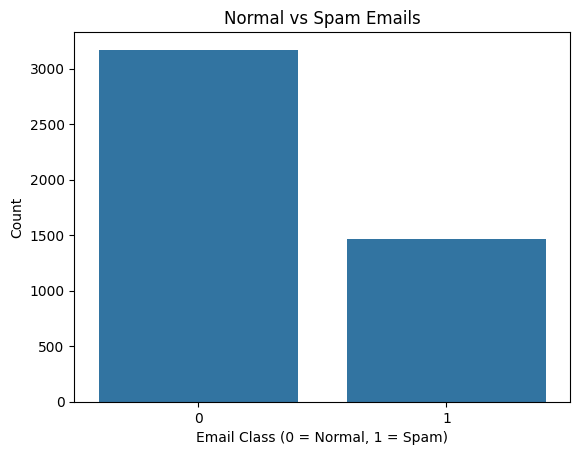

In [5]:
# Class distribution plot
sns.countplot(x=y)
plt.title("Normal vs Spam Emails")
plt.xlabel("Email Class (0 = Normal, 1 = Spam)")
plt.ylabel("Count")
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3704, 3000)
Testing Data: (927, 3000)


In [7]:
#Build and train the KNN model
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)

pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, pred_knn))

KNN Accuracy: 0.8468176914778857


In [8]:
#Build and train the SVM model
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

svm.fit(X_train, y_train)

pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, pred_svm))

SVM Accuracy: 0.9363538295577131


In [9]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, pred_knn),
        accuracy_score(y_test, pred_svm)
    ],
    "Precision": [
        precision_score(y_test, pred_knn),
        precision_score(y_test, pred_svm)
    ],
    "Recall": [
        recall_score(y_test, pred_knn),
        recall_score(y_test, pred_svm)
    ],
    "F1 Score": [
        f1_score(y_test, pred_knn),
        f1_score(y_test, pred_svm)
    ]
})

print(results)

  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.846818   0.682039  0.962329  0.798295
1   SVM  0.936354   0.884488  0.917808  0.900840


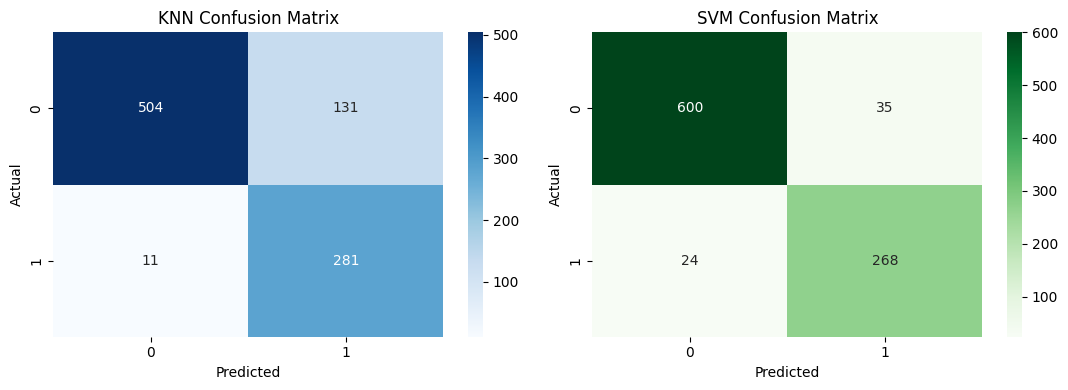

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(
    confusion_matrix(y_test, pred_knn),
    annot=True, fmt="d", cmap="Blues", ax=ax[0]
)
ax[0].set_title("KNN Confusion Matrix")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, pred_svm),
    annot=True, fmt="d", cmap="Greens", ax=ax[1]
)
ax[1].set_title("SVM Confusion Matrix")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

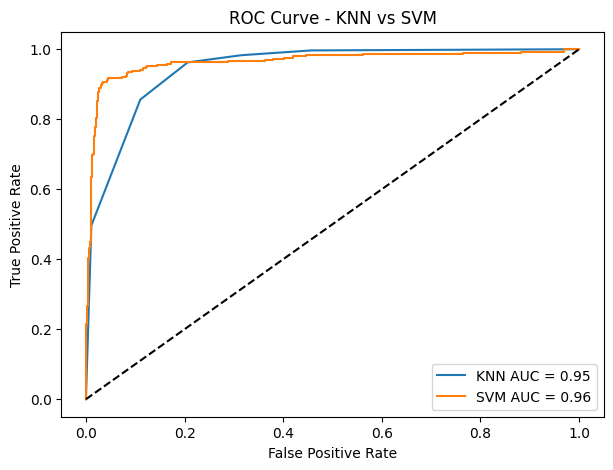

In [11]:
# Get prediction scores
knn_scores = knn.predict_proba(X_test)[:, 1]
svm_scores = svm.decision_function(X_test)

# Calculate ROC values
fpr_knn, tpr_knn, _ = roc_curve(y_test, knn_scores)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_scores)

auc_knn = auc(fpr_knn, tpr_knn)
auc_svm = auc(fpr_svm, tpr_svm)

# Plot ROC curves
plt.figure(figsize=(7, 5))

plt.plot(fpr_knn, tpr_knn, label=f"KNN AUC = {auc_knn:.2f}")
plt.plot(fpr_svm, tpr_svm, label=f"SVM AUC = {auc_svm:.2f}")

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN vs SVM")
plt.legend()
plt.show()

In [12]:
print("KNN Classification Report:")
print(classification_report(y_test, pred_knn))

print("\nSVM Classification Report:")
print(classification_report(y_test, pred_svm))

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.79      0.88       635
           1       0.68      0.96      0.80       292

    accuracy                           0.85       927
   macro avg       0.83      0.88      0.84       927
weighted avg       0.89      0.85      0.85       927


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       635
           1       0.88      0.92      0.90       292

    accuracy                           0.94       927
   macro avg       0.92      0.93      0.93       927
weighted avg       0.94      0.94      0.94       927

